# Categorical profile analysis: census, difficulty, rarity (no-alarm ROI)

**Region.** No-alarm rows with `y_prob <= 0.02` — the score only draws the boundary; it plays no part in any measurement below. ~590k rows, 1,674 frauds, 0.28% base rate.

**Working categorical profile (v3).** The categorical space after all audits and decisions:

- `merchant_tier` — 3 tiers from the EDA lift table (hot / warm / background)
- `auth_method` — 5 levels (the amplifier; never reduce)
- `device_type` — 8 levels
- `is_new_merchant` — 2 levels (worth ~+0.009 AUC; never drop)

That is 3 x 5 x 8 x 2 = **240 theoretical cells**. Dropped entirely: the time features (independence established), `channel` and `card_type` (label-flat), `prior_disputes` and `txn_count_last_24h` (weak / carried by velocity). The earlier binarizations of the counting columns are retired — counting columns go through the honest numeric pipeline below.

**The plan, four steps:**

0. **Census.** Effective cells, occupancy distribution, frauds per cell.
1. **Feature prep.** Columns with < 20 unique values (only `cvv_retry_count`) become their *smoothed fraud probability* (m-estimate). All other numerics (8 columns) become their *within-cell decile* — the row's position inside its pocket.
2. **Difficulty.** For each fraud: the maximum number of decile columns it shares with a *single* non-fraudulent transaction of the same cell (nearest-neighbor overlap, 0-8). High = has a near-perfect double; low = numerically alone in its crowd.
3. **Rarity.** Per row and numeric: **A** = min(P(X<=t), P(X>=t)) — two-sided tail mass in [0, 0.5], measured within the cell (ROI-global fallback for thin cells); **B** = classic |z| (mean/sd); **C** = robust |z| (median / 1.4826*MAD). The product of A across features simulates a joint distribution mass (reported as log10; a ranking device, not an absolute mass). Count estimators: #features with A < 0.05 / 0.10, |B| >= 2.5 / 3, |C| >= 2.5 / 3.

**The gold question (step 4).** If a good number of the 1,674 frauds sit at joint-mass values where almost no non-fraud lives — while the model scores them at their cell background — then rarity features are exactly what the model is missing, and they become the next fold-safe dataset version.

Pre-registered cautions: the A-product is uniformly tiny (use ranks and counts, not the raw value); B explodes on heavy-tailed money columns (C is the primary deviation scale).


In [ ]:

%load_ext autoreload
%autoreload 2

import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from ccf_ml import file_utils
from ccf_ml.cross_validation import alarm as alarm_mod
importlib.reload(file_utils)
importlib.reload(alarm_mod)

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    ID_COLUMN,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
    get_training_oof_path,
)

DELIMITER = "-" * 60
NOTEBOOK_STEM = "categorical_profile_rarity"
EXP_NAME = "hgb_baseline"
SCORE_CUT = 0.02

# --- working categorical profile (v3): 3 x 5 x 8 x 2 = 240 cells ----------
MERCHANT_TIERS = {
    "hot": ("Gift Cards", "Crypto Exchange", "Gaming"),
    "warm": ("Electronics", "Streaming"),
    "background": (
        "Travel", "Utilities", "Healthcare", "Fuel",
        "Restaurants", "Groceries", "Online Retail",
    ),
}
TIER_BY_MERCHANT = {
    merchant: tier
    for tier, merchants in MERCHANT_TIERS.items()
    for merchant in merchants
}
FP_COLUMNS = ("merchant_tier", "auth_method", "device_type", "is_new_merchant")

# --- numeric pipeline -------------------------------------------------------
# < 20 unique values -> smoothed fraud probability (step 1, branch a)
LOW_UNIQUE_COLUMNS = ("cvv_retry_count",)
# >= 20 unique values -> within-cell deciles (step 1, branch b)
NUMERIC_COLUMNS = (
    "amount_usd",
    "hours_since_last_txn",
    "distance_from_home_km",
    "card_age_months",
    "customer_age",
    "account_balance_usd",
    "velocity_score",
    "merchant_risk_score",
)

M_SMOOTH = 50        # m-estimate weight for the smoothed probabilities
MIN_CELL_LOCAL = 100  # cells below this size use ROI-global rarity statistics

tables_dir = get_script_table_dir(NOTEBOOK_STEM)


def load_region() -> pd.DataFrame:
    """Return the no-alarm, y_prob <= 0.02 rows with the tier column attached.

    Joins the training table to the baseline OOF scores purely to draw the
    region boundary; no score is used in any later measurement.
    """
    train_df = pd.read_csv(get_train_csv_path())
    oof_df = pd.read_csv(get_training_oof_path(EXP_NAME))
    features = train_df.drop(columns=[TARGET_COLUMN])
    frame = features.merge(oof_df, on=ID_COLUMN, how="inner", validate="one_to_one")
    if len(frame) != len(train_df) or len(frame) != len(oof_df):
        raise ValueError(
            f"join lost rows: train={len(train_df)} oof={len(oof_df)} joined={len(frame)}"
        )
    has_alarm = alarm_flag_mask(frame, columns=ALARM_FLAG_COLUMNS)
    region = frame.loc[(~has_alarm) & (frame["y_prob"] <= SCORE_CUT)].copy()
    region["merchant_tier"] = region["merchant_category"].map(TIER_BY_MERCHANT)
    if region["merchant_tier"].isna().any():
        raise ValueError("unmapped merchant category inside the region")
    return region


region = load_region()
N_REGION = len(region)
N_FRAUD = int((region[TARGET_COLUMN] == 1).sum())
RATE_REGION = N_FRAUD / N_REGION
print(f"region rows: {N_REGION}")
print(f"region frauds: {N_FRAUD}")
print(f"region fraud rate: {RATE_REGION:.6f}")
print("footprint levels:", {c: int(region[c].nunique()) for c in FP_COLUMNS})


region rows: 590070
region frauds: 1674
region fraud rate: 0.002837
footprint levels: {'merchant_tier': 3, 'auth_method': 5, 'device_type': 8, 'is_new_merchant': 2}


## Step 0: census of the 240-cell space

How many cells actually exist, how many rows sit behind a cell (occupancy), and how the 1,674 frauds spread over cells. Cells under `MIN_CELL_LOCAL` rows are flagged — later steps fall back to ROI-global statistics for them.


                                           0
theoretical_cells                 240.000000
observed_cells                    240.000000
cells_ge_min_local                184.000000
median_cell_size                  477.000000
share_rows_in_cells_ge_min_local    0.996338
cells_with_fraud                  175.000000
median_frauds_per_fraud_cell        4.000000
max_frauds_in_a_cell               98.000000
------------------------------------------------------------
cell size percentiles
count      240.0
mean      2458.6
std       5813.8
min          2.0
10%         22.0
25%        111.0
50%        477.0
75%       1961.2
90%       5368.8
99%      31577.2
max      43136.0
------------------------------------------------------------
cells with the most fraud
merchant_tier       auth_method   device_type  is_new_merchant  n_cell  n_fraud     rate
   background         3D Secure Android Phone            False   43136       98 0.002272
   background               OTP Android Phone            Fal

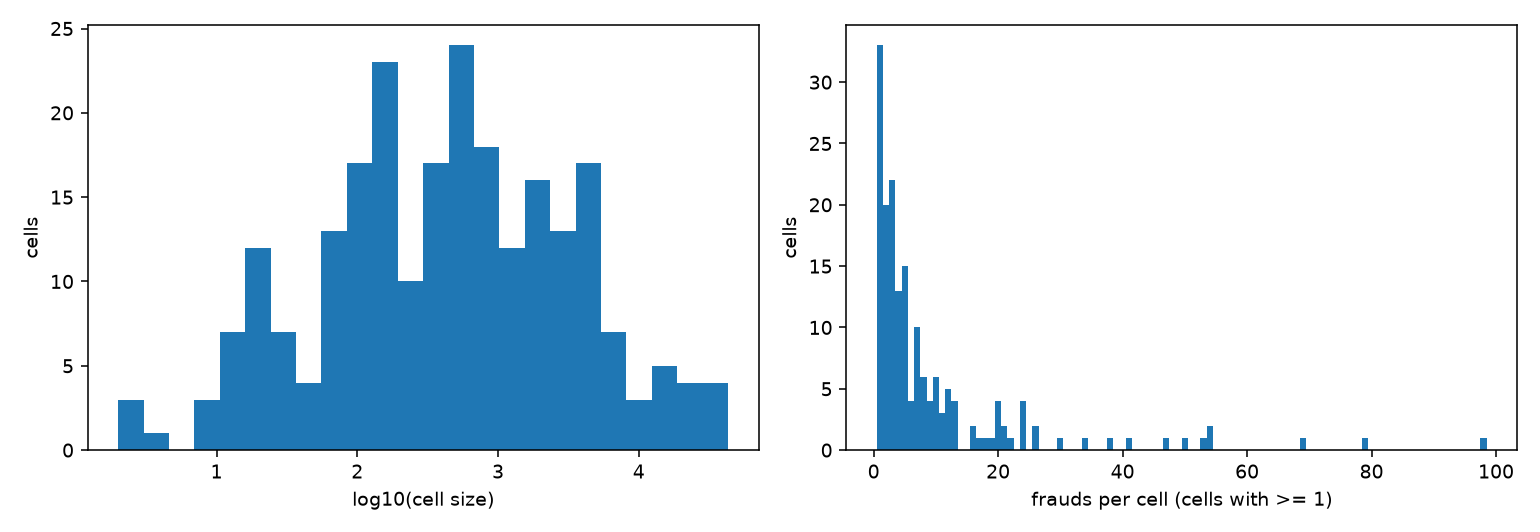

In [ ]:
def cell_census(region: pd.DataFrame) -> pd.DataFrame:
    """One row per footprint cell: size, fraud count, fraud rate."""
    stats = (
        region.groupby(list(FP_COLUMNS), observed=True)[TARGET_COLUMN]
        .agg(n_cell="size", n_fraud="sum")
        .reset_index()
    )
    stats["rate"] = stats["n_fraud"] / stats["n_cell"]
    return stats.sort_values("n_cell", ascending=False).reset_index(drop=True)


def census_summary(cell_stats: pd.DataFrame) -> dict[str, object]:
    """Headline numbers of the categorical cell space."""
    fraud_cells = cell_stats.loc[cell_stats["n_fraud"] > 0, "n_fraud"]
    return {
        "theoretical_cells": 3 * 5 * 8 * 2,
        "observed_cells": len(cell_stats),
        "cells_ge_min_local": int((cell_stats["n_cell"] >= MIN_CELL_LOCAL).sum()),
        "median_cell_size": float(cell_stats["n_cell"].median()),
        "share_rows_in_cells_ge_min_local": float(
            cell_stats.loc[cell_stats["n_cell"] >= MIN_CELL_LOCAL, "n_cell"].sum()
        ) / N_REGION,
        "cells_with_fraud": int(fraud_cells.shape[0]),
        "median_frauds_per_fraud_cell": float(fraud_cells.median()),
        "max_frauds_in_a_cell": int(fraud_cells.max()),
    }


cell_stats = cell_census(region)
summary = census_summary(cell_stats)
print(pd.DataFrame([summary]).transpose().to_string())
print(DELIMITER)
print("cell size percentiles")
print(cell_stats["n_cell"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(1).to_string())
print(DELIMITER)
print("cells with the most fraud")
print(cell_stats.sort_values("n_fraud", ascending=False).head(8).to_string(index=False))
cell_stats.to_csv(tables_dir / "census_cells.csv", index=False)
print("saved", tables_dir / "census_cells.csv")

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="census")
fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.8))
axes[0].hist(np.log10(cell_stats["n_cell"].to_numpy(dtype=np.float64)), bins=24)
axes[0].set_xlabel("log10(cell size)")
axes[0].set_ylabel("cells")
fraud_cells = cell_stats.loc[cell_stats["n_fraud"] > 0, "n_fraud"]
axes[1].hist(fraud_cells.to_numpy(dtype=np.float64), bins=np.arange(0.5, fraud_cells.max() + 1.5, 1.0))
axes[1].set_xlabel("frauds per cell (cells with >= 1)")
axes[1].set_ylabel("cells")
fig.tight_layout()
fig.savefig(plot_dir / "census.png", dpi=140)
print("saved", plot_dir / "census.png")
plt.show()


## Step 1: prepare the numeric features

Two branches, decided by the number of unique values:

- **< 20 uniques** (only `cvv_retry_count` qualifies): each value becomes its *smoothed fraud probability*, `(n_v * rate_v + m * prior) / (n_v + m)` with `m = 50` — an m-estimate that shrinks small levels toward the region rate.
- **>= 20 uniques** (the 8 numerics): each row becomes its *within-cell decile* (0-9) — the row's rank position inside its own footprint cell. Pocket-relative position is the theme of the whole analysis; a global decile would ignore the pocket.


In [ ]:
 
def smoothed_probability_map(
    values: pd.Series, targets: pd.Series, m: int
) -> pd.Series:
    """m-estimate fraud probability per value, indexed by value.

    (n_v * rate_v + m * prior) / (n_v + m): levels with few rows shrink
    toward the region rate, busy levels keep their empirical rate.
    """
    counts = values.value_counts()
    frame = pd.DataFrame({"n": counts})
    frame["n_fraud"] = values.to_frame().assign(y=targets.to_numpy()).groupby(values.name)["y"].sum()
    prior = float(targets.mean())
    frame["smoothed"] = (frame["n_fraud"] + m * prior) / (frame["n"] + m)
    return frame["smoothed"]


def add_smoothed_probability(region: pd.DataFrame, column: str, m: int) -> None:
    """Replace `column` usage by its smoothed fraud probability column."""
    mapping = smoothed_probability_map(region[column], region[TARGET_COLUMN], m)
    region[column + "_p_fraud"] = region[column].map(mapping)
    return mapping


def add_within_cell_deciles(region: pd.DataFrame, columns: tuple[str, ...]) -> None:
    """Add dec_<column>: rank percentile inside the footprint cell, 0-9.

    The percentile is computed inside each cell (pocket-relative position);
    ties share the average rank, the decile floor caps at 9.
    """
    grouped = region.groupby(list(FP_COLUMNS), observed=True)
    for column in columns:
        pct = grouped[column].rank(pct=True).to_numpy(dtype=np.float64)
        region["dec_" + column] = np.minimum((pct * 10.0).astype(np.int64), 9)


# -- which branch does each numeric take? ------------------------------------
unique_counts = {
    column: int(region[column].nunique())
    for column in LOW_UNIQUE_COLUMNS + NUMERIC_COLUMNS
}
print("unique values per numeric (threshold: 20)")
print(pd.Series(unique_counts).sort_values().to_string())
print(DELIMITER)

cvv_map = add_smoothed_probability(region, "cvv_retry_count", M_SMOOTH)
cvv_table = pd.DataFrame({
    "n": region["cvv_retry_count"].value_counts(),
    "n_fraud": region.groupby("cvv_retry_count", observed=True)[TARGET_COLUMN].sum(),
})
cvw_rate = region.groupby("cvv_retry_count", observed=True)[TARGET_COLUMN].mean()
cvv_table["rate"] = cvw_rate
cvv_table["smoothed_p"] = cvv_map
print("cvv_retry_count -> smoothed fraud probability (m =", M_SMOOTH, ")")
print(cvv_table.round(5).to_string())
print(DELIMITER)

add_within_cell_deciles(region, NUMERIC_COLUMNS)
decile_columns = ["dec_" + column for column in NUMERIC_COLUMNS]
print("within-cell decile columns:", decile_columns)
# sanity: within a big cell the deciles should be near-uniform (10% each)
big_cell = cell_stats.iloc[0]
big_mask = np.ones(len(region), dtype=bool)
for column in FP_COLUMNS:
    big_mask &= (region[column].to_numpy() == big_cell[column])
print("decile shares inside the largest cell (should be ~10% each):")
print(
    pd.Series(region.loc[big_mask, "dec_amount_usd"]).value_counts(normalize=True)
    .sort_index().round(3).to_string()
)


unique values per numeric (threshold: 20)
cvv_retry_count              4
card_age_months             49
customer_age                64
velocity_score             648
merchant_risk_score        942
hours_since_last_txn      3584
distance_from_home_km     4312
amount_usd               12365
account_balance_usd      40666
------------------------------------------------------------
cvv_retry_count -> smoothed fraud probability (m = 50 )
                      n  n_fraud     rate  smoothed_p
cvv_retry_count                                      
0                559283     1445  0.00258     0.00258
1                 30432      226  0.00743     0.00742
2                   350        3  0.00857     0.00785
3                     5        0  0.00000     0.00258
------------------------------------------------------------
within-cell decile columns: ['dec_amount_usd', 'dec_hours_since_last_txn', 'dec_distance_from_home_km', 'dec_card_age_months', 'dec_customer_age', 'dec_account_balance_usd', 'de

## Step 2: difficulty — nearest-neighbor decile overlap

For each fraudulent transaction: scan every non-fraudulent transaction of the *same cell* and count, for the best-matching one, how many of the 8 decile columns agree. Score 0-8:

- **8**: a near-perfect double exists — the fraud is numerically indistinguishable from one specific clean row at decile resolution.
- **0-2**: numerically isolated — no clean row in the cell looks like it even column-by-column.

Computed with chunked fraud x non-fraud boolean match matrices per cell (same machinery as the earlier twin analysis).


difficulty = max decile columns shared with one non-fraud of the same cell
difficulty
0      1
1      2
2      2
3     36
4    320
5    917
6    378
7     18
------------------------------------------------------------
share with difficulty 8 (near-perfect double): 0.000
share with difficulty >= 7: 0.011
share with difficulty <= 2 (numerically isolated): 0.003
median difficulty: 5
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\categorical_profile_rarity\tables\difficulty.csv
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\categorical_profile_rarity\plots\difficulty\difficulty.png


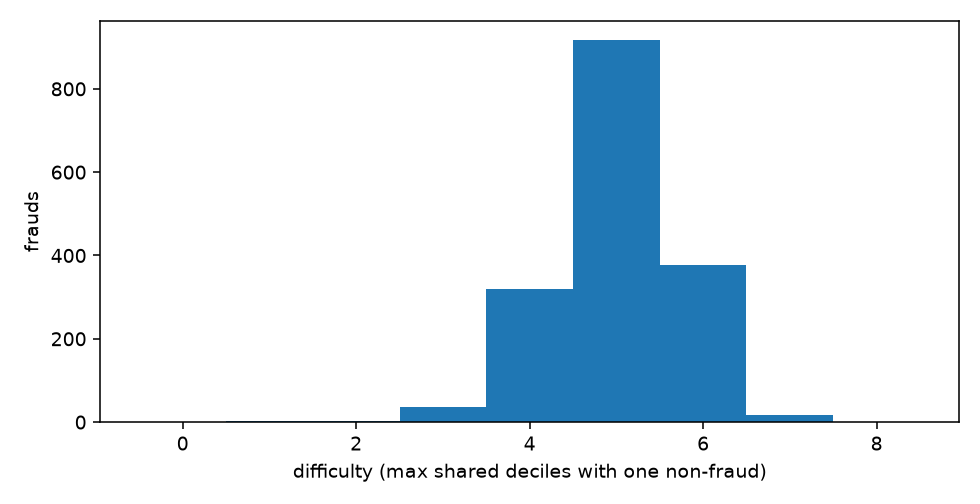

In [ ]:
 
def difficulty_max_overlap(
    region: pd.DataFrame, decile_columns: list[str], *, fraud_chunk: int = 16
) -> pd.DataFrame:
    """Per fraud: max shared-decile count with a single non-fraud in its cell."""
    dec_matrix = region[decile_columns].to_numpy(dtype=np.int64)
    y_arr = region[TARGET_COLUMN].to_numpy(dtype=np.int64)
    cell_arr = region[list(FP_COLUMNS)].astype(str).agg("|".join, axis=1).to_numpy()
    ids = region[ID_COLUMN].to_numpy()
    n_cols = len(decile_columns)
    rows: list[dict[str, object]] = []
    for cell_key in pd.unique(cell_arr[y_arr == 1]):
        in_cell = np.flatnonzero(cell_arr == cell_key)
        fraud_pos = in_cell[y_arr[in_cell] == 1]
        nonfraud_pos = in_cell[y_arr[in_cell] == 0]
        if len(nonfraud_pos) == 0:
            for pos in fraud_pos:
                rows.append(
                    {"id": int(ids[pos]), "n_cell": len(in_cell), "difficulty": -1}
                )
            continue
        f_dec = dec_matrix[fraud_pos]
        n_dec = dec_matrix[nonfraud_pos]
        best = np.zeros(len(fraud_pos), dtype=np.int64)
        for start in range(0, len(fraud_pos), fraud_chunk):
            stop = min(start + fraud_chunk, len(fraud_pos))
            matches = (f_dec[start:stop, None, :] == n_dec[None, :, :]).sum(axis=2)
            best[start:stop] = matches.max(axis=1)
        for k in range(len(fraud_pos)):
            rows.append(
                {
                    "id": int(ids[fraud_pos[k]]),
                    "n_cell": len(in_cell),
                    "difficulty": int(best[k]),
                }
            )
    return pd.DataFrame(rows)


difficulty = difficulty_max_overlap(region, decile_columns)
print("difficulty = max decile columns shared with one non-fraud of the same cell")
print(difficulty["difficulty"].value_counts().sort_index().to_string())
print(DELIMITER)
n = len(difficulty)
print(f"share with difficulty 8 (near-perfect double): {(difficulty['difficulty'] == 8).mean():.3f}")
print(f"share with difficulty >= 7: {(difficulty['difficulty'] >= 7).mean():.3f}")
print(f"share with difficulty <= 2 (numerically isolated): {(difficulty['difficulty'] <= 2).mean():.3f}")
print(f"median difficulty: {difficulty['difficulty'].median():.0f}")
difficulty.to_csv(tables_dir / "difficulty.csv", index=False)
print("saved", tables_dir / "difficulty.csv")

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="difficulty")
fig, ax = plt.subplots(figsize=(7.0, 3.6))
ax.hist(difficulty["difficulty"].to_numpy(dtype=np.float64), bins=np.arange(-0.5, 9.5, 1.0))
ax.set_xlabel("difficulty (max shared deciles with one non-fraud)")
ax.set_ylabel("frauds")
fig.tight_layout()
fig.savefig(plot_dir / "difficulty.png", dpi=140)
print("saved", plot_dir / "difficulty.png")
plt.show()


## Step 3: rarity — tail mass, z-scores, joint mass

Per row and numeric (the 8 decile columns' raw values):

- **A** = min(P(X <= t), P(X >= t)) — the two-sided tail mass at the row's value, measured against the **cell's** empirical distribution (ROI-global fallback for cells under `MIN_CELL_LOCAL` rows). In [0, 0.5]; small = the value sits deep in a tail of its pocket.
- **B** = |x - mean| / sd (classic z). Fragile on heavy tails; reference only.
- **C** = |x - median| / (1.4826 * MAD) (robust z). Primary deviation scale. Degenerate references (sd = 0 or MAD = 0) fall back to the ROI-global scale.

**Joint estimators**: `joint_log10` = sum of log10(A) over the 8 features — the simulated joint distribution mass under independence (a *ranking* device; the raw product is uniformly tiny). Count estimators: number of features with A < 0.05 / 0.10, |B| >= 2.5 / 3, |C| >= 2.5 / 3.


In [ ]:
def tail_mass_a(sorted_ref: np.ndarray, x: np.ndarray) -> np.ndarray:
    """A = min(P(X <= t), P(X >= t)) of x against the sorted reference sample."""
    n = len(sorted_ref)
    lo = np.searchsorted(sorted_ref, x, side="left")
    hi = np.searchsorted(sorted_ref, x, side="right")
    p_le = hi / n
    p_ge = (n - lo) / n
    return np.minimum(p_le, p_ge)


def z_classic(ref: np.ndarray, x: np.ndarray) -> tuple[np.ndarray, bool]:
    """|x - mean| / sd against the reference; ok=False when sd == 0."""
    sd = float(ref.std(ddof=1))
    if sd <= 0.0:
        return np.zeros(len(x)), False
    return np.abs(x - float(ref.mean())) / sd, True


def z_robust(ref: np.ndarray, x: np.ndarray) -> tuple[np.ndarray, bool]:
    """|x - median| / (1.4826 * MAD); ok=False when MAD == 0."""
    mad = float(np.median(np.abs(ref - np.median(ref))))
    if mad <= 0.0:
        return np.zeros(len(x)), False
    return np.abs(x - float(np.median(ref))) / (1.4826 * mad), True


def add_rarity_features(
    region: pd.DataFrame, columns: tuple[str, ...], *, min_cell: int
) -> None:
    """Add A_/B_/C_ per column, joint_log10, and the count estimators.

    Reference distribution = the row's own cell (self-inclusive, like the
    twin analysis) when the cell holds at least `min_cell` rows, otherwise
    the whole ROI. Degenerate local scales (sd or MAD of 0) fall back to the
    ROI scale; a column degenerate at both scales gets a zero score.
    """
    n_rows = len(region)
    values = {
        column: region[column].to_numpy(dtype=np.float64) for column in columns
    }
    global_sorted = {
        column: np.sort(values[column]) for column in columns
    }
    a_cols = {column: np.full(n_rows, np.nan) for column in columns}
    b_cols = {column: np.full(n_rows, np.nan) for column in columns}
    c_cols = {column: np.full(n_rows, np.nan) for column in columns}
    cell_codes = region[list(FP_COLUMNS)].astype(str).agg("|".join, axis=1).to_numpy()
    for cell_key in np.unique(cell_codes):
        pos = np.flatnonzero(cell_codes == cell_key)
        use_local = len(pos) >= min_cell
        for column in columns:
            x = values[column][pos]
            ref = np.sort(x) if use_local else global_sorted[column]
            a_cols[column][pos] = tail_mass_a(ref, x)
            b, b_ok = z_classic(ref, x)
            if use_local and not b_ok:
                b, b_ok = z_classic(global_sorted[column], x)
            if not b_ok:
                b = np.zeros(len(x))
            c, c_ok = z_robust(ref, x)
            if use_local and not c_ok:
                c, c_ok = z_robust(global_sorted[column], x)
            if not c_ok:
                c = np.zeros(len(x))
            b_cols[column][pos] = b
            c_cols[column][pos] = c
    for column in columns:
        region["A_" + column] = a_cols[column]
        region["B_" + column] = b_cols[column]
        region["C_" + column] = c_cols[column]
    a_matrix = np.column_stack([a_cols[column] for column in columns])
    b_matrix = np.column_stack([b_cols[column] for column in columns])
    c_matrix = np.column_stack([c_cols[column] for column in columns])
    region["joint_log10"] = np.log10(a_matrix).sum(axis=1)
    region["n_A_lt_005"] = (a_matrix < 0.05).sum(axis=1)
    region["n_A_lt_010"] = (a_matrix < 0.10).sum(axis=1)
    region["n_B_ge_25"] = (b_matrix >= 2.5).sum(axis=1)
    region["n_B_ge_30"] = (b_matrix >= 3.0).sum(axis=1)
    region["n_C_ge_25"] = (c_matrix >= 2.5).sum(axis=1)
    region["n_C_ge_30"] = (c_matrix >= 3.0).sum(axis=1)
    a_frame = region.loc[:, ["A_" + column for column in columns]]
    if a_frame.isna().to_numpy().any():
        raise ValueError("rarity left NaNs")


add_rarity_features(region, NUMERIC_COLUMNS, min_cell=MIN_CELL_LOCAL)
fraud_mask = region[TARGET_COLUMN] == 1
summary_rows = []
for name, column in (
    ("joint_log10 (rarer = more negative)", "joint_log10"),
    ("n_A_lt_005", "n_A_lt_005"),
    ("n_A_lt_010", "n_A_lt_010"),
    ("n_B_ge_25", "n_B_ge_25"),
    ("n_C_ge_25", "n_C_ge_25"),
    ("n_C_ge_30", "n_C_ge_30"),
):
    fraud_values = region.loc[fraud_mask, column]
    clean_values = region.loc[~fraud_mask, column]
    summary_rows.append(
        {
            "estimator": name,
            "fraud_median": float(fraud_values.median()),
            "clean_median": float(clean_values.median()),
            "fraud_mean": float(fraud_values.mean()),
            "clean_mean": float(clean_values.mean()),
        }
    )
print("fraud vs non-fraud rarity summary")
print(pd.DataFrame(summary_rows).round(4).to_string(index=False))
region.to_parquet(tables_dir / "region_with_rarity.parquet", index=False)
print("saved", tables_dir / "region_with_rarity.parquet")


fraud vs non-fraud rarity summary
                          estimator  fraud_median  clean_median  fraud_mean  clean_mean
joint_log10 (rarer = more negative)       -5.6841        -5.599     -5.8745     -5.7411
                         n_A_lt_005        1.0000         1.000      0.7838      0.7045
                         n_A_lt_010        2.0000         1.000      1.6290      1.5527
                          n_B_ge_25        0.0000         0.000      0.1535      0.1277
                          n_C_ge_25        0.0000         0.000      0.4253      0.3619
                          n_C_ge_30        0.0000         0.000      0.2867      0.2505
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\categorical_profile_rarity\tables\region_with_rarity.parquet


## Step 4: the gold check

Three questions:

1. **Standalone power** — how well does rarity alone rank fraud inside the ROI? (AUC of each estimator against the label.)
2. **Separation** — do frauds sit in rarer joint-mass regions than non-frauds? (Share of frauds below the non-fraud joint-mass deciles.)
3. **The model tie-in** — do the *buried* frauds (worse-ranked by the model) carry lower joint mass? If yes, rarity is exactly the signal the model is missing, and it becomes the next fold-safe feature version. If rarity and model rank agree, the model already knows.


standalone ranking power inside the ROI
                          estimator  standalone_auc
joint rarity (rarer = higher score)         0.52834
                         n_A_lt_005         0.52220
                         n_A_lt_010         0.51832
                          n_B_ge_25         0.51165
                          n_B_ge_30         0.50525
                          n_C_ge_25         0.52571
                          n_C_ge_30         0.51557
------------------------------------------------------------
frauds below the non-fraud 1% joint-mass quantile: 0.015
frauds below the non-fraud 5% joint-mass quantile: 0.068
frauds below the non-fraud 10% joint-mass quantile: 0.130
------------------------------------------------------------
model tie-in (better-ranked half vs worse-ranked half of the 1,674)
  median joint_log10: better -5.883 | worse -5.557
  median n_A_lt_005:  better 1 | worse 1
------------------------------------------------------------
the 10 rarest frauds (lowest 

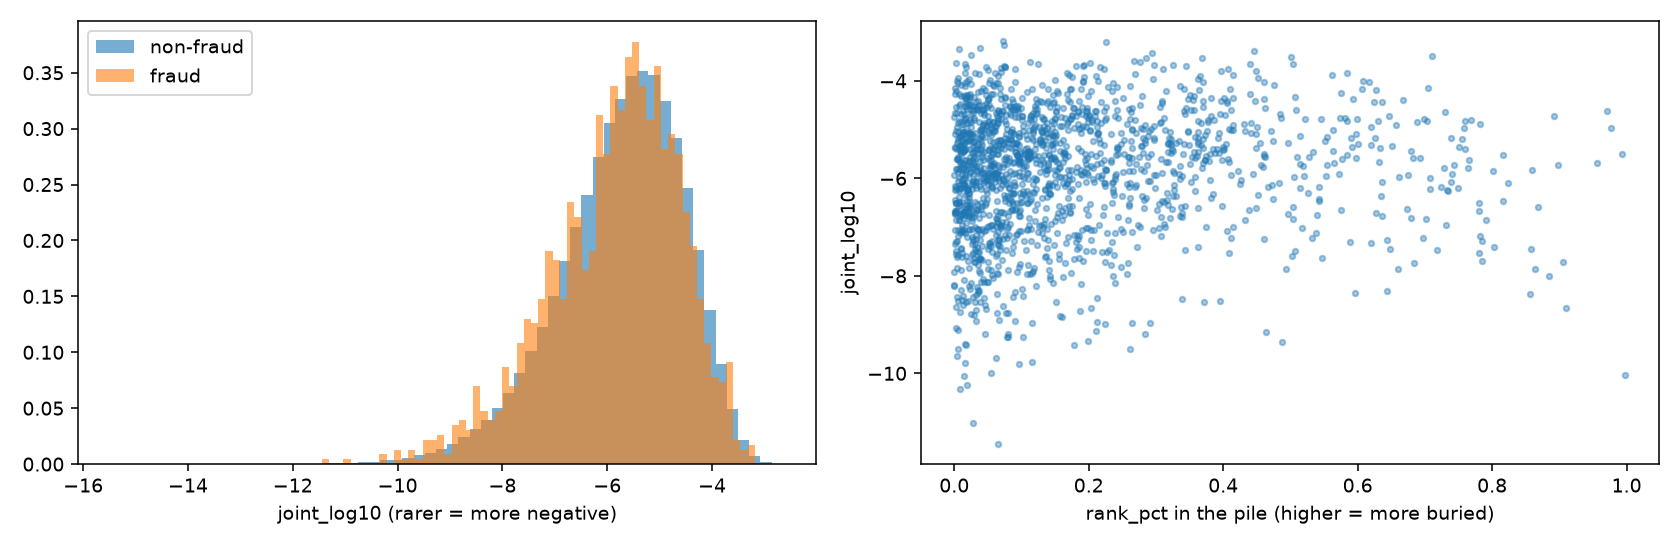

In [ ]:
 
def standalone_auc(region: pd.DataFrame, score_column: str, *, ascending: bool) -> float:
    """AUC of a single estimator against the label inside the ROI."""
    score = region[score_column].to_numpy(dtype=np.float64)
    if not ascending:
        score = -score
    return float(roc_auc_score(region[TARGET_COLUMN], score))


def bottom_share(fraud_values: np.ndarray, clean_values: np.ndarray, q: float) -> float:
    """Share of frauds below the q-quantile of the non-fraud distribution."""
    threshold = np.quantile(clean_values, q)
    return float((fraud_values < threshold).mean())


auc_rows = []
for name, column, ascending in (
    ("joint rarity (rarer = higher score)", "joint_log10", False),
    ("n_A_lt_005", "n_A_lt_005", True),
    ("n_A_lt_010", "n_A_lt_010", True),
    ("n_B_ge_25", "n_B_ge_25", True),
    ("n_B_ge_30", "n_B_ge_30", True),
    ("n_C_ge_25", "n_C_ge_25", True),
    ("n_C_ge_30", "n_C_ge_30", True),
):
    auc_rows.append(
        {"estimator": name, "standalone_auc": round(standalone_auc(region, column, ascending=ascending), 5)}
    )
print("standalone ranking power inside the ROI")
print(pd.DataFrame(auc_rows).to_string(index=False))
print(DELIMITER)

fraud_joint = region.loc[fraud_mask, "joint_log10"].to_numpy(dtype=np.float64)
clean_joint = region.loc[~fraud_mask, "joint_log10"].to_numpy(dtype=np.float64)
for q in (0.01, 0.05, 0.10):
    print(
        f"frauds below the non-fraud {q:.0%} joint-mass quantile: "
        f"{bottom_share(fraud_joint, clean_joint, q):.3f}"
    )
print(DELIMITER)

ranks_path = get_script_table_dir("oof_alarm_region_auc") / "no_alarm_p_le_0p02_fraud_ranks.csv"
ranks = pd.read_csv(ranks_path)
fraud_rows = region.loc[fraud_mask].merge(
    ranks[[ID_COLUMN, "rank", "rank_pct"]], on=ID_COLUMN, how="left", validate="one_to_one"
)
if fraud_rows["rank"].isna().any():
    raise ValueError("some frauds are missing ranks")
median_rank = fraud_rows["rank_pct"].median()
better = fraud_rows.loc[fraud_rows["rank_pct"] < median_rank]
worse = fraud_rows.loc[fraud_rows["rank_pct"] >= median_rank]
print("model tie-in (better-ranked half vs worse-ranked half of the 1,674)")
print(f"  median joint_log10: better {better['joint_log10'].median():.3f} | worse {worse['joint_log10'].median():.3f}")
print(f"  median n_A_lt_005:  better {better['n_A_lt_005'].median():.0f} | worse {worse['n_A_lt_005'].median():.0f}")
print(DELIMITER)
fraud_rows = fraud_rows.merge(difficulty[[ID_COLUMN, "difficulty"]], on=ID_COLUMN, how="left", validate="one_to_one")
gold = fraud_rows.sort_values("joint_log10").head(10)
print("the 10 rarest frauds (lowest joint mass) and how the model scores them")
print(
    gold[[ID_COLUMN, "y_prob", "rank_pct", "difficulty", "n_A_lt_005", "n_C_ge_30", "joint_log10"]]
    .round(4).to_string(index=False)
)
fraud_rows.to_csv(tables_dir / "fraud_rarity.csv", index=False)
print("saved", tables_dir / "fraud_rarity.csv")

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="gold_check")
fig, axes = plt.subplots(1, 2, figsize=(12.0, 3.9))
axes[0].hist(clean_joint, bins=60, density=True, alpha=0.6, label="non-fraud")
axes[0].hist(fraud_joint, bins=60, density=True, alpha=0.6, label="fraud")
axes[0].set_xlabel("joint_log10 (rarer = more negative)")
axes[0].legend()
axes[1].scatter(
    fraud_rows["rank_pct"].to_numpy(dtype=np.float64),
    fraud_rows["joint_log10"].to_numpy(dtype=np.float64),
    s=8,
    alpha=0.4,
)
axes[1].set_xlabel("rank_pct in the pile (higher = more buried)")
axes[1].set_ylabel("joint_log10")
fig.tight_layout()
fig.savefig(plot_dir / "gold_check.png", dpi=140)
print("saved", plot_dir / "gold_check.png")
plt.show()


## Takeaway

1. **Census.** All 240 theoretical cells exist; median cell 477 rows; 99.6% of rows live in cells with >= 100 rows; 175 cells hold fraud with a median of 4 frauds each. The v3 footprint is a healthy partition.

2. **cvv_retry_count smoothed probabilities** (m = 50): 0 -> 0.26%, 1 -> 0.74%, 2 -> 0.79%, 3 (5 rows) -> shrunk to the prior. The earlier binarization's 2.6x lift is confirmed and refined into a dose-response.

3. **Difficulty.** Median fraud shares 5 of 8 deciles with its single best-matching non-fraud; 1.1% reach >= 7, zero reach 8, 0.3% sit at <= 2. Frauds are mid-spectrum: no full doubles, almost no numerically isolated rows.

4. **Rarity.** Frauds are only mildly rarer than non-frauds: median joint_log10 -5.68 vs -5.60, and 1.5x / 1.4x / 1.3x enrichment in the bottom 1% / 5% / 10% of the non-fraud joint-mass distribution. Standalone ranking power is weak: joint rarity 0.528 AUC, every count estimator between 0.505 and 0.526.

5. **The gold hypothesis is refuted.** The model's *better*-ranked frauds are the *rarer* ones (median joint_log10 -5.88 vs -5.56 for the buried half), and 9 of the 10 rarest frauds already sit near the top of the pile (rank_pct 0.007-0.115). The model does not miss rare rows; it misses ordinary-looking ones. Rarity features would duplicate signal the trees already extract - consistent with the three feature-engineering nulls.

6. **What remains.** The buried frauds are mid-spectrum on difficulty and rarity: indistinguishable from their crowd by every measure built so far (twins, profiles, deciles, tail mass, z-scores). This strengthens the noise-floor reading of the leftover error inside this region: the 1,674 are not hiding in rare corners - most of them simply look like everyone else at every resolution we can measure.